# 2. Análisis exploratorio (EDA)
Se explora la serie horaria de PM2.5 de Curva de Maroñas usando **solo el período de desarrollo (2024–2025)**. El test no se mira, para no tomar decisiones con información del futuro. El objetivo no es producir todos los gráficos posibles, sino detectar estructuras que cambien decisiones del modelo: estacionalidad, estabilidad de la serie y rezagos útiles.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

URL_HORARIO = "https://raw.githubusercontent.com/trajano-carballo/paa-pronostico-pm25-montevideo/main/data/processed/pm25_horario_preprocesado.csv"
df = pd.read_csv(URL_HORARIO)
df["hora"] = pd.to_datetime(df["hora"], utc=True).dt.tz_convert("America/Montevideo")

# EDA solo con desarrollo y Curva de Maroñas (el test no se mira)
dev = (df[(df["estacion"] == "Curva de Maroñas") & (df["particion"] == "desarrollo")]
       .set_index("hora").sort_index())
y = dev["pm25"]          # valores reales, con NaN donde no hay dato
print(dev.index.min(), dev.index.max(), len(dev), f"NaN: {y.isna().mean():.1%}")

2024-01-01 00:00:00-03:00 2025-12-31 23:00:00-03:00 17544 NaN: 7.1%


## 2.1 Serie completa y nivel
Se grafica la serie horaria completa con su media móvil de 7 días. Se busca:
- **Tendencia o cambios de nivel:** si la media móvil sube, baja o salta de forma sostenida.
- **Episodios extremos:** picos aislados frente a períodos de nivel alto sostenido.
- **Huecos:** los cortes de la línea son los faltantes que quedaron sin interpolar.
- **Estabilidad:** si el comportamiento al principio, en el medio y al final de 2024–2025 es comparable.

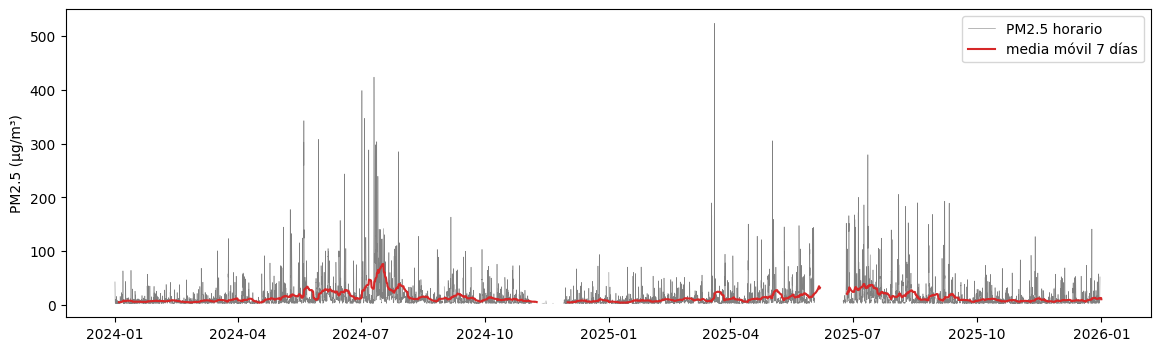

In [2]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y.index, y, lw=0.4, color="gray", label="PM2.5 horario")
ax.plot(y.index, y.rolling(24*7, min_periods=24*3).mean(), color="C3", lw=1.5, label="media móvil 7 días")
ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend(); plt.show()

**Conclusión.** La serie mantiene un nivel base bajo (la media móvil de 7 días queda casi siempre por debajo de ~15 µg/m³) y no se observa una tendencia sostenida a lo largo de 2024–2025. Sobre ese nivel aparecen aumentos temporales y picos horarios aislados de hasta ~520 µg/m³. Se distinguen dos huecos largos, en noviembre de 2024 y junio de 2025, que permanecen como faltantes.

## 2.2 Patrones de calendario
Se compara el nivel y la dispersión de PM2.5 según la hora del día, el día de la semana y el mes. Se busca:
- **Hora del día:** si hay un ciclo diario marcado (horas pico y horas bajas) y qué tan ancha es la banda entre cuartiles. Orienta los rezagos diarios (24 y 48 h).
- **Día de la semana:** si los fines de semana difieren de los días hábiles. Orienta el uso de variables de calendario.
- **Día del mes:** si el nivel o la dispersión cambian según el día del mes. Orienta si conviene usar esta variable de calendario.
- **Mes:** si el nivel y la dispersión cambian entre meses.

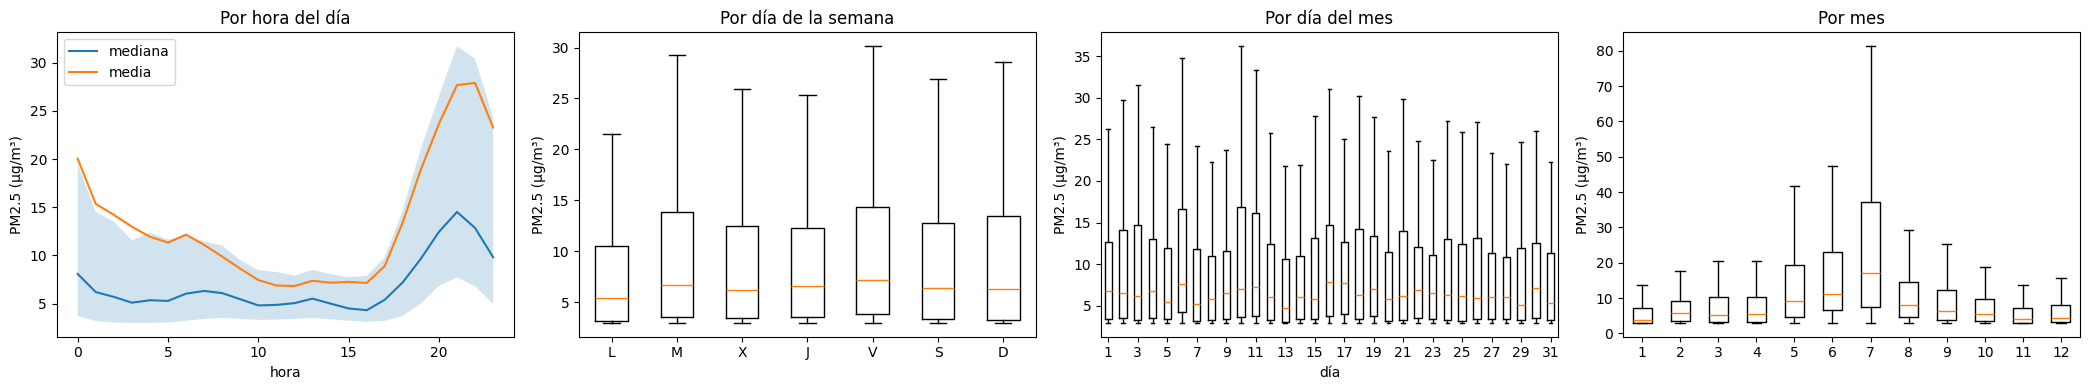

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(21, 4))

# Hora del día
h = y.groupby(y.index.hour)
axs[0].plot(h.median(), label="mediana"); axs[0].plot(h.mean(), label="media")
axs[0].fill_between(range(24), h.quantile(.25), h.quantile(.75), alpha=0.2)
axs[0].set(title="Por hora del día", xlabel="hora"); axs[0].legend()

# Día de la semana
axs[1].boxplot([y[y.index.dayofweek == k].dropna() for k in range(7)], showfliers=False)
axs[1].set_xticklabels(["L", "M", "X", "J", "V", "S", "D"]); axs[1].set_title("Por día de la semana")

# Día del mes
axs[2].boxplot([y[y.index.day == k].dropna() for k in range(1, 32)], showfliers=False)
axs[2].set_xticks(range(1, 32, 2)); axs[2].set_xticklabels(range(1, 32, 2))
axs[2].set_title("Por día del mes"); axs[2].set_xlabel("día")

# Mes
axs[3].boxplot([y[y.index.month == k].dropna() for k in range(1, 13)], showfliers=False)
axs[3].set_xticklabels(range(1, 13)); axs[3].set_title("Por mes")

for a in axs: a.set_ylabel("PM2.5 (µg/m³)")
plt.tight_layout(); plt.show()

**Conclusión.** Hay un ciclo diario claro: los valores son bajos durante el día (mediana ≈5 µg/m³ entre las 10 y 16 h) y suben desde la tarde hasta un máximo entre las 20 y 22 h (mediana ≈14 y media ≈28 µg/m³), con mayor dispersión en esas horas. Esto respalda usar rezagos de 24 y 48 h y/o la hora del día como variable. Por día de la semana no se observan diferencias marcadas. Por día del mes tampoco se observan diferencias sistemáticas: las medianas se mantienen en un rango estrecho (≈5-7 µg/m³) y las variaciones en cajas y máximos no siguen un patrón, lo que es compatible con la influencia de episodios aislados. Por lo tanto, el EDA no aporta evidencia a favor del día del mes, pero se lo considera como variable de calendario candidata y su aporte se evaluará mediante backtesting junto con las demás. Por mes, mayo a julio muestran mayor nivel y dispersión, con máximo en julio; el resto del año es bajo y similar.

## 2.3 ¿El patrón mensual se repite entre 2024 y 2025?
Se compara la mediana mensual de cada año. Si las dos curvas tienen forma parecida, hay indicios de un patrón anual; si difieren, con solo dos años no hay base sólida para apoyarse en él. Hay que tener en cuenta que junio de 2025 tiene pocos datos por un hueco de 21 días, así que esa comparación es incompleta.

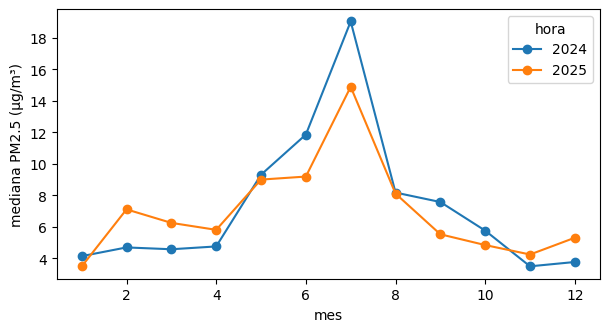

In [4]:
mm = y.groupby([y.index.year, y.index.month]).median().unstack(0)
mm.plot(marker="o", figsize=(7, 3.5), ylabel="mediana PM2.5 (µg/m³)", xlabel="mes"); plt.show()

**Conclusión.** Las curvas de 2024 y 2025 tienen una forma parecida: nivel bajo de enero a abril, aumento desde mayo, máximo en julio en ambos años y descenso posterior. Hay indicios de un patrón anual, pero con solo dos años (y junio de 2025 incompleto) no se puede afirmar estacionalidad anual. Por eso no se apoyará el modelo en ella; el mes podrá evaluarse como variable de calendario en el backtesting.

## 2.4 Estacionariedad
Una serie es aproximadamente estacionaria cuando su nivel, su dispersión y su relación con el pasado se mantienen estables en el tiempo. Interesa porque el modelo aprende en 2024–2025 una relación entre rezagos y valor futuro, y si esa relación cambia, lo aprendido deja de servir. Para valorarlo se revisan cuatro cosas:
1. **Media y desvío móvil:** si el nivel y la dispersión cambian a lo largo del tiempo.
2. **Comparación por trimestres:** si la distribución (cuantiles) es parecida entre tramos.
3. **Pruebas ADF y KPSS:** evidencia estadística complementaria, que no reemplaza a los gráficos.

La estacionariedad no es un requisito para los modelos que usaremos, pero un cambio fuerte de nivel o de dispersión puede dificultar la generalización.

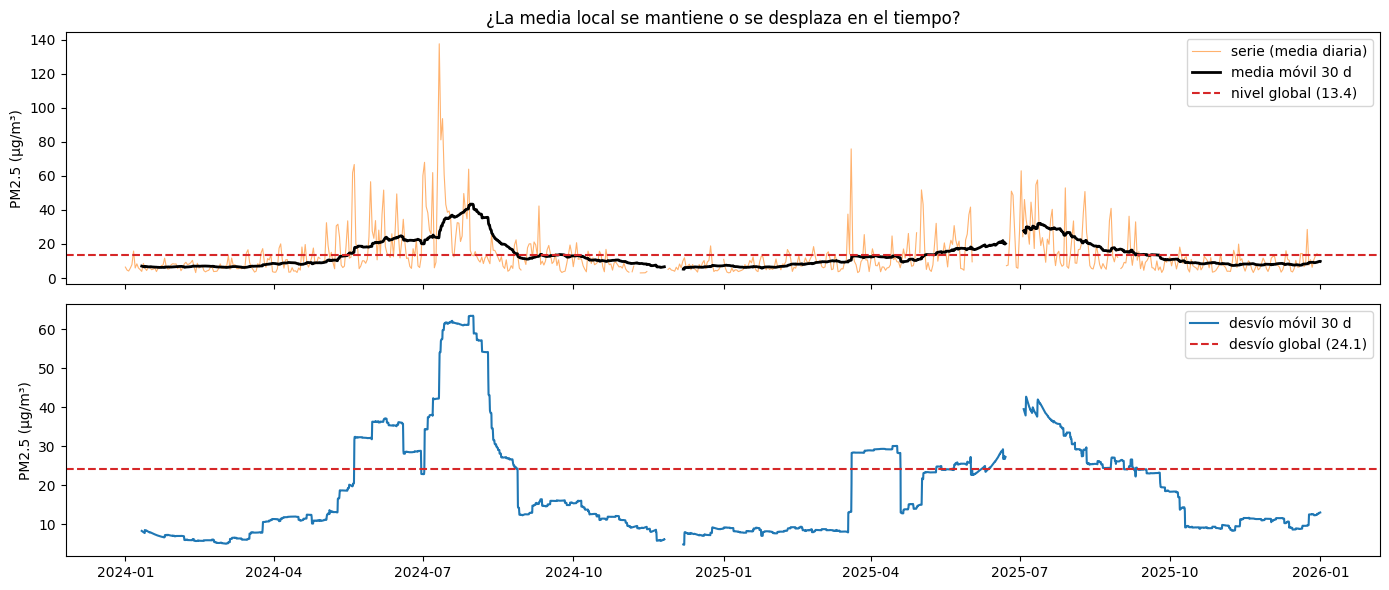

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

diaria = y.resample("D").mean()
m30 = y.rolling(24*30, min_periods=24*10).mean()
s30 = y.rolling(24*30, min_periods=24*10).std()

axs[0].plot(diaria, color="C1", lw=0.8, alpha=0.6, label="serie (media diaria)")
axs[0].plot(m30, color="k", lw=2, label="media móvil 30 d")
axs[0].axhline(y.mean(), color="C3", ls="--", label=f"nivel global ({y.mean():.1f})")
axs[0].set_ylabel("PM2.5 (µg/m³)"); axs[0].legend(loc="upper right")
axs[0].set_title("¿La media local se mantiene o se desplaza en el tiempo?")

axs[1].plot(s30, color="C0", lw=1.5, label="desvío móvil 30 d")
axs[1].axhline(y.std(), color="C3", ls="--", label=f"desvío global ({y.std():.1f})")
axs[1].set_ylabel("PM2.5 (µg/m³)"); axs[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

In [6]:
(y.groupby(y.index.to_period("Q"))
  .describe(percentiles=[.25, .5, .75, .95])[["count", "mean", "std", "25%", "50%", "75%", "95%"]]
  .round(1))

/tmp/ipykernel_2491/1477049364.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  (y.groupby(y.index.to_period("Q"))


,count,mean,std,25%,50%,75%,95%
hora,,,,,,,
2024Q1,2180.0,7.2,8.2,3.1,4.5,7.8,19.5
2024Q2,2131.0,16.7,26.2,4.1,8.7,17.8,56.9
2024Q3,2181.0,22.6,40.9,5.4,10.0,20.4,87.2
2024Q4,1634.0,8.0,9.5,3.1,4.5,8.2,25.2
2025Q1,2157.0,9.5,18.2,3.2,5.3,10.0,26.7
2025Q2,1650.0,16.0,24.4,3.9,7.3,15.6,56.9
2025Q3,2182.0,18.0,27.4,4.0,8.4,18.2,66.2
2025Q4,2182.0,8.7,11.1,3.2,4.8,8.8,27.6


In [7]:
from statsmodels.tsa.stattools import adfuller, kpss

x = dev["pm25_modelo"]
nan = x.isna(); grupo = nan.cumsum()
largo = x[~nan].groupby(grupo[~nan]).size()
tramo = x[~nan][grupo[~nan] == largo.idxmax()]      # tramo continuo más largo
print("Tramo:", tramo.index.min(), "→", tramo.index.max(), f"({len(tramo)} h)")
print("ADF  p-valor:", round(adfuller(tramo, autolag="AIC")[1], 4))
print("KPSS p-valor:", round(kpss(tramo, regression="c", nlags="auto")[1], 4))

Tramo: 2024-05-01 00:00:00-03:00 → 2024-08-30 23:00:00-03:00 (2928 h)
ADF  p-valor: 0.0
KPSS p-valor: 0.0486


/tmp/ipykernel_2491/1123291252.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ADF  p-valor:", round(adfuller(tramo, autolag="AIC")[1], 4))
/tmp/ipykernel_2491/1123291252.py:9: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("KPSS p-valor:", round(kpss(tramo, regression="c", nlags="auto")[1], 4))


**Conclusión.** El nivel base se mantiene en 2024–2025, pero la dispersión no es constante: en los trimestres de mayor nivel (abril a septiembre) la media, el desvío y el percentil 95 son claramente más altos que en el resto del año, en ambos años. Por ejemplo, el desvío trimestral es de ~8–11 en Q1 y Q4 (salvo Q1 de 2025, por el episodio del 20/03) frente a ~24–41 en Q2 y Q3. El nivel y la dispersión cambian juntos y por episodios. Las pruebas ADF (p ≈ 0) y KPSS (p = 0.0486, en el límite) se hicieron sobre el tramo continuo más largo, de solo cuatro meses (mayo–agosto de 2024), por lo que no son concluyentes. Se considera la serie aproximadamente estable en nivel, pero con variabilidad que depende de la época. No se aplica ninguna transformación por ahora; se evaluará en el backtesting.

## 2.5 ACF y PACF: memoria de la serie
Se estudia cuánto se parece el valor de una hora a los valores de horas anteriores, para orientar qué rezagos (lags) ofrecerle al modelo.
- **ACF:** correlación entre el valor actual y el de hace *k* horas. Incluye efectos indirectos (si hace 1 h influye en ahora y hace 2 h influye en hace 1 h, el rezago 2 también aparece correlacionado). Sirve para detectar ciclos, como un pico en 24 o 48 h.
- **PACF:** correlación directa con el rezago *k* una vez quitado el efecto de los rezagos intermedios. Sirve para ver cuántos rezagos consecutivos aportan información propia.

Como la serie tiene huecos, la ACF se calcula con los pares de datos disponibles y la PACF con una regresión que usa solo las filas completas (el mismo criterio con que entrenará el modelo). Estos gráficos solo orientan: los rezagos finales se eligen con backtesting.

/tmp/ipykernel_2491/3757410544.py:7: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a, ic = acf(x.to_numpy(), nlags=NLAGS, missing="conservative", alpha=0.05)


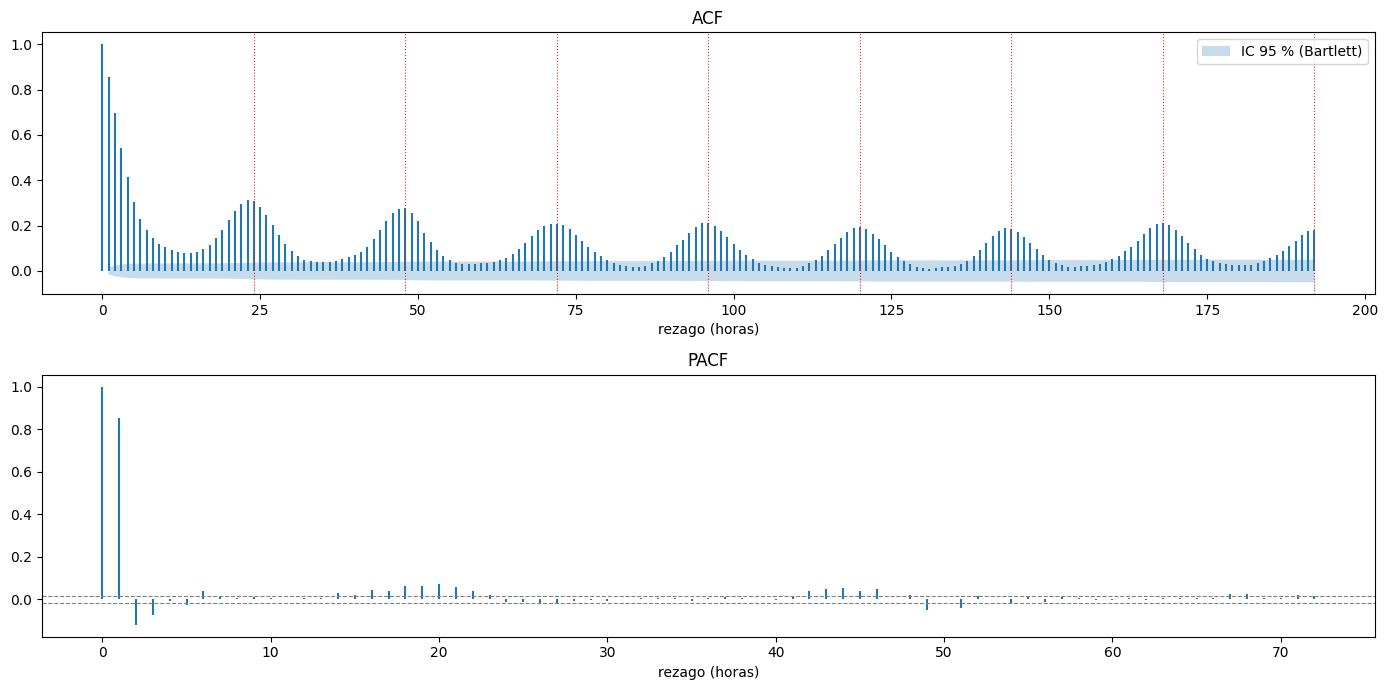

,1,2,3,6,12,24,48,72,96,120,144,168,192
ACF,0.853,0.696,0.543,0.231,0.085,0.307,0.279,0.209,0.212,0.195,0.187,0.210,0.181
IC ±,0.015,0.024,0.028,0.033,0.034,0.036,0.040,0.043,0.045,0.046,0.047,0.049,0.050


In [8]:
from statsmodels.tsa.stattools import acf

x = dev["pm25_modelo"]
NLAGS = 192                     # 8 días: permite ver el rezago de 168 h

# ACF con intervalo de confianza del 95 % (fórmula de Bartlett); con NaN usa solo los pares disponibles
a, ic = acf(x.to_numpy(), nlags=NLAGS, missing="conservative", alpha=0.05)
ancho = ic[:, 1] - a            # semiancho del intervalo, centrado en 0 como en plot_acf

# PACF: coeficiente del rezago k en una regresión con los rezagos 1..k,
# usando solo filas completas (igual criterio que dropna_from_series=True)
def pacf_completo(x, K):
    v = x.to_numpy(); out = [1.0]
    for k in range(1, K + 1):
        X = np.column_stack([v[k - j:len(v) - j] for j in range(1, k + 1)])
        yy = v[k:]
        m = ~np.isnan(X).any(axis=1) & ~np.isnan(yy)
        A = np.column_stack([np.ones(m.sum()), X[m]])
        out.append(np.linalg.lstsq(A, yy[m], rcond=None)[0][-1])
    return np.array(out)

p = pacf_completo(x, 72)
banda = 1.96 / np.sqrt(x.notna().sum())   # banda constante para la PACF

fig, axs = plt.subplots(2, 1, figsize=(14, 7))
axs[0].vlines(range(NLAGS + 1), 0, a)
axs[0].fill_between(range(1, NLAGS + 1), -ancho[1:], ancho[1:], alpha=0.25, label="IC 95 % (Bartlett)")
axs[0].set_title("ACF"); axs[0].legend(loc="upper right")
for k in (24, 48, 72, 96, 120, 144, 168, 192):
    axs[0].axvline(k, color="C3", ls=":", lw=0.8)

axs[1].vlines(range(73), 0, p)
axs[1].axhline(banda, color="gray", ls="--", lw=0.8); axs[1].axhline(-banda, color="gray", ls="--", lw=0.8)
axs[1].set_title("PACF")
for ax in axs: ax.set_xlabel("rezago (horas)")
plt.tight_layout(); plt.show()

lags = [1, 2, 3, 6, 12, 24, 48, 72, 96, 120, 144, 168, 192]
pd.DataFrame({"ACF": a[lags], "IC ±": ancho[lags]}, index=lags).round(3).T

**Conclusión.** La ACF muestra una memoria corta fuerte (0.85, 0.70 y 0.54 en los rezagos 1, 2 y 3) y un ciclo diario: aparecen picos anchos cerca de 24 h (0.31) y 48 h (0.28), y luego repetidos cada 24 h con valores de ~0.2. El PACF indica que la dependencia directa se concentra en el rezago 1 (0.85), con valores pequeños en los rezagos 2 y 3 (negativos) y valores despreciables más allá, aunque muchos superan la banda por el gran número de datos. En la ACF el rezago de 168 h (0.21) no se distingue de los de 144 y 192 h, por lo que no hay evidencia de un efecto semanal propio, coherente con la ausencia de diferencias por día de la semana en 2.2. Como candidatos se consideran los rezagos 1 a 3 y 24 y 48, y los rezagos finales se elegirán comparando conjuntos en el backtesting.